# SMS Spam with DistilBERT: does a pretrained language model earn its keep?

**The question:** the legacy notebook fine-tuned **DistilBERT** (a small, pretrained language model) to spot spam text messages and reported about 99% accuracy on a random 20% of the messages. 99% sounds like the end of the story. *But a good old bag-of-words model scores nearly as high, and the SMS data contain many exact duplicate messages. So how much does DistilBERT really add? Where does it help (when there are few labelled examples? when spammers disguise their words?), where does it hurt, can we trust its confidence, and what does a mistake cost?* The comparison partner is the best model of the TF-IDF notebook: word and character TF-IDF with logistic regression.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the messages
4. Hypotheses and why we chose each test
5. The two models
6. The legacy evaluation, replayed
7. H1: does DistilBERT beat the baseline on fair validation?
8. H2: does it help most when labelled data are scarce?
9. H3: does it see through disguised spam?
10. H4: can we trust its confidence, and what does a mistake cost?
11. Looking at the mistakes
12. Takeaways
13. Limitations

**Run it:** `uv run jupyter lab NLP/sms-spam-distilbert/sms_spam_distilbert.ipynb`, or *Run All* in any Jupyter. The data (a small zip from UCI) and DistilBERT (about 270 MB from the Hugging Face hub) download themselves on the first run. It uses a GPU if present and takes about 25 minutes on one.

## 1. 💡 The simple analogy

Imagine two **mail clerks** sorting your post into "keep" and "junk".

- **The word-counting clerk** has a checklist of words and word-pieces that junk mail uses ("FREE", "claim", "txt", a lot of digits). He gets very good very quickly, but he reads the *letters*, not the *meaning*.
- **The well-read clerk (DistilBERT)** has already read millions of pages before the first day, so he knows that "winner" and "w1nn3r" are cousins and that "ring me if you are around" is a friend. He needs fewer examples to learn the job, but he is more expensive, slower, and sometimes **too sure of himself**.
- If you test them on letters **they have already seen** (duplicates), both look brilliant. A fair test uses letters neither has seen.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the maximum message length (64 word-pieces) and the learning rate (0.00005) keeps the notebook reproducible and avoids "magic numbers". The seeds are fixed and the GPU is set to deterministic mode, so the same run gives the same results.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import csv
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub.utils import logging as hub_logging
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
MODEL_NAME = "distilbert-base-uncased"
SEED = 365
MAX_LEN = 64
BATCH = 32
LEARNING_RATE = 5e-5
N_FOLDS = 5
N_BOOTSTRAP = 2_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the messages

*What:* the **UCI SMS Spam Collection**, 5,574 English text messages labelled spam or ham (not spam). We read the file carefully (a default CSV reader silently drops two messages that contain quote characters), look at how many exact duplicate texts there are, and measure message length in **word-pieces** (the units DistilBERT reads). *Why:* duplicates decide whether a random split is fair, and length decides how much of a message the model sees.

> **Problems in the legacy notebook this replaces:** a random 80/20 split of messages that include many exact duplicates, so test messages can have identical twins in the training set; accuracy as the only metric on data that is 87% ham; no baseline to compare with; a single run; and TensorFlow's `TFTrainer`, which has since been removed from the transformers library (so it no longer runs); it also read the file with a default CSV reader that drops two messages.

In [2]:
def load_sms() -> pd.DataFrame:
    """Downloads the UCI SMS Spam Collection (once, into ``data/``) and loads it.

    Returns:
        One row per message with columns ``label`` ("ham" or "spam") and ``message``.

    Raises:
        ValueError: If the file does not have the expected number of messages.
    """
    path = DATA_DIR / "SMSSpamCollection"
    if not path.exists():
        archive = DATA_DIR / "sms_spam_collection.zip"
        urllib.request.urlretrieve(DATA_URL, archive)
        with zipfile.ZipFile(archive) as zf:
            zf.extract("SMSSpamCollection", DATA_DIR)
    table = pd.read_csv(
        path, sep="\t", names=["label", "message"], encoding="utf-8", quoting=csv.QUOTE_NONE
    )
    if len(table) != 5_574 or set(table["label"]) != {"ham", "spam"}:
        raise ValueError("Unexpected SMS Spam Collection file")
    return table


sms = load_sms()
y = (sms["label"] == "spam").astype(int).to_numpy()
texts = sms["message"]
groups = pd.factorize(texts.str.lower().str.strip())[0]  # identical texts share a group
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
lengths = np.array([len(ids) for ids in tok(list(texts))["input_ids"]])
print(
    f"{len(sms):,} messages, {y.sum()} spam ({y.mean():.1%}); {len(set(groups)):,} distinct texts"
)
print(
    f"Length in word pieces: median {np.median(lengths):.0f}, 95th percentile "
    f"{np.percentile(lengths, 95):.0f}, longest {lengths.max()}; "
    f"share longer than {MAX_LEN}: {(lengths > MAX_LEN).mean():.1%}"
)
print(f"Device: {DEVICE}")

5,574 messages, 747 spam (13.4%); 5,159 distinct texts
Length in word pieces: median 20, 95th percentile 55, longest 238; share longer than 64: 1.8%
Device: cuda


**How to read this:**

- **5,574 messages, 747 spam (13.4%).** A model that always says "ham" would score 86.6% accuracy, so accuracy alone says little; we also use **average precision** (how well the model ranks spam above ham) and the **spam recall and false-alarm rate**.
- **Only 5,159 distinct texts:** about 7% of the messages are exact repeats. We keep identical texts together in the same fold whenever we validate, so no message has a twin on the other side of the split.
- **Messages are short:** median **20** word-pieces, 95th percentile **55**, longest 238; only **1.8%** are longer than our 64-piece limit, so almost no message is cut.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | On fair validation, is DistilBERT better than the TF-IDF baseline? | Same | Differs | 5-fold validation keeping duplicates together; exact McNemar test on the 5,574 out-of-fold predictions |
| H2 | Does DistilBERT help most when labelled examples are few? | The gap is the same at every training size | The gap shrinks as data grows | Learning curve from 25 to 4,459 messages, 3 seeds per size; paired Wilcoxon test |
| H3 | Does DistilBERT see through disguised spam (letters swapped for look-alike digits)? | Both lose the same share of spam | Differs | Spam recall at 4 disguise levels; exact McNemar test |
| H4 | Is DistilBERT's stated confidence honest, and is it the cheaper model when a false alarm costs 10 times a miss? | Both are equally honest and cheap | Differs | Expected calibration error with a bootstrap interval; total cost at several thresholds |

*Why these tests?* The two models are scored on the **same messages**, so the exact **McNemar test**, which uses only the messages where they disagree, is the right comparison. Averages of average precision over 5 folds say how large the gap is, and the per-fold differences say whether it is consistent.

## 5. The two models

*What:*

- **DistilBERT** (`distilbert-base-uncased`, 67 million weights) with a two-way classification layer, fine-tuned with AdamW (learning rate 0.00005, batches of 32, a linear schedule with 10% warm-up). Each run trains for at least 3 passes and at least about 60 update steps.
- **The baseline:** word (1-2 words) and character (2-5 letters) TF-IDF features and logistic regression, the best classical model of the TF-IDF notebook.
- Both output a **probability of spam**; we call a message spam above 0.5 unless stated otherwise.

> **Problems in the legacy code this replaces:** it trained once on the legacy split without fixing the training seed, reported accuracy only, and relied on `TFTrainer`, which no longer exists.

In [3]:
enc = tok(
    list(texts), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt"
)
ids_all, mask_all = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
labels_all = torch.tensor(y, device=DEVICE)


def encode_texts(new_texts: list[str]) -> tuple[torch.Tensor, torch.Tensor]:
    """Turns new messages into padded word-piece ids and attention masks on the device."""
    e = tok(
        new_texts, padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt"
    )
    return e["input_ids"].to(DEVICE), e["attention_mask"].to(DEVICE)


def finetune(train_idx: np.ndarray, seed: int, epochs: int | None = None):
    """Fine-tunes DistilBERT to tell spam from ham.

    Args:
        train_idx: Indices of the training messages.
        seed: Seed for the new classification layer and the batch order.
        epochs: Number of passes; by default at least 3 and at least about 60 update steps.

    Returns:
        The fine-tuned model in evaluation mode.
    """
    torch.manual_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    model = model.to(DEVICE)
    steps_per_epoch = int(np.ceil(len(train_idx) / BATCH))
    n_epochs = epochs or max(3, int(np.ceil(60 / steps_per_epoch)))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total = n_epochs * steps_per_epoch
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total), total)
    index = torch.tensor(train_idx, device=DEVICE)
    for _ in range(n_epochs):
        model.train()
        order = torch.randperm(len(index), device=DEVICE)
        for start in range(0, len(index), BATCH):
            pick = index[order[start : start + BATCH]]
            out = model(
                input_ids=ids_all[pick], attention_mask=mask_all[pick], labels=labels_all[pick]
            )
            optimizer.zero_grad()
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
    return model.eval()


@torch.no_grad()
def spam_probability(model, ids: torch.Tensor, mask: torch.Tensor) -> np.ndarray:
    """Probability of spam for each encoded message.

    Args:
        model: A fine-tuned classifier.
        ids: Word-piece ids, shape (n, MAX_LEN).
        mask: Attention masks, same shape.

    Returns:
        Spam probabilities, shape (n,).
    """
    out = []
    for start in range(0, len(ids), 256):
        logits = model(
            input_ids=ids[start : start + 256], attention_mask=mask[start : start + 256]
        ).logits
        out.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(out)


def make_baseline() -> Pipeline:
    """Word + character TF-IDF with logistic regression, the best model of the TF-IDF project."""
    word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)
    return Pipeline(
        [
            ("vec", FeatureUnion([("word", word), ("char", char)])),
            ("clf", LogisticRegression(C=10, max_iter=2000)),
        ]
    )


def summarise(truth: np.ndarray, prob: np.ndarray) -> dict[str, float]:
    """Average precision, accuracy, spam recall and ham false-alarm rate at the 0.5 threshold."""
    pred = prob > 0.5
    return {
        "ap": average_precision_score(truth, prob),
        "accuracy": float((pred == truth).mean()),
        "recall": float(pred[truth == 1].mean()),
        "false_alarm": float(pred[truth == 0].mean()),
    }


n_params = sum(
    p.numel()
    for p in AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2
    ).parameters()
)
print(f"DistilBERT classifier: {n_params / 1e6:.1f} million weights")

DistilBERT classifier: 67.0 million weights


**How to read this:** the classifier has **67.0 million** weights. Its job is to be worth it.

## 6. The legacy evaluation, replayed

*What:* a random 80/20 split of the messages (seed 0, as in the legacy notebook), DistilBERT fine-tuned for 2 passes. We count how many test messages have an **exact copy in the training set**. *Why:* to see what the legacy number really measured.

In [4]:
legacy_train, legacy_test = train_test_split(np.arange(len(sms)), test_size=0.2, random_state=0)
legacy_model = finetune(legacy_train, seed=0, epochs=2)
legacy_prob = spam_probability(legacy_model, ids_all[legacy_test], mask_all[legacy_test])
legacy_pred = legacy_prob > 0.5
truth = y[legacy_test]
copy = np.isin(groups[legacy_test], groups[legacy_train])
print("Legacy-style split (random 80/20, seed 0), DistilBERT fine-tuned for 2 epochs:")
print(
    f"  accuracy {(legacy_pred == truth).mean():.4f} on {len(truth):,} test messages; "
    f"errors: {int((legacy_pred != truth).sum())} "
    f"({int(((legacy_pred == 1) & (truth == 0)).sum())} false alarms, "
    f"{int(((legacy_pred == 0) & (truth == 1)).sum())} missed spam)"
)
print(f"  test messages with an exact copy in the training set: {copy.mean():.1%}")
if (~copy).any():
    print(
        f"  accuracy on test messages with a copy in training: "
        f"{(legacy_pred[copy] == truth[copy]).mean():.4f}; without a copy: "
        f"{(legacy_pred[~copy] == truth[~copy]).mean():.4f}"
    )

Legacy-style split (random 80/20, seed 0), DistilBERT fine-tuned for 2 epochs:
  accuracy 0.9937 on 1,115 test messages; errors: 7 (0 false alarms, 7 missed spam)
  test messages with an exact copy in the training set: 11.3%
  accuracy on test messages with a copy in training: 1.0000; without a copy: 0.9929


**How to read this:**

- **The legacy-style number is reproduced:** accuracy **99.37%** on 1,115 test messages, with 7 mistakes (**0 false alarms**, 7 missed spam).
- **But 11.3% of the test messages have an exact twin in the training set,** and on those twins the model is **100%** right, against **99.29%** on messages without one. The leak is small here, because the twins are mostly easy, but it adds a little to every score from a random split.
- **A single random split is also a single draw:** the next section uses five folds with identical messages kept together.

## 7. H1: does DistilBERT beat the baseline on fair validation?

*What:* **5-fold validation** where every group of identical messages stays in one fold, fine-tuning DistilBERT afresh on each fold's training part and scoring the held-out part. The baseline gets the same folds. That gives **5,574 out-of-fold predictions per model**. We compare accuracy, average precision, spam recall and false-alarm rate, and test the disagreement with an exact McNemar test. *Why:* every message is judged by a model that has not seen it or its twins.

In [5]:
splitter = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
folds = list(splitter.split(texts, y, groups))
oof_bert = np.zeros(len(sms))
oof_base = np.zeros(len(sms))
fold_rows = []
fold_models = {}
for k, (tr, te) in enumerate(folds):
    model = finetune(tr, seed=k)
    oof_bert[te] = spam_probability(model, ids_all[te], mask_all[te])
    base = make_baseline().fit(texts.iloc[tr], y[tr])
    oof_base[te] = base.predict_proba(texts.iloc[te])[:, 1]
    fold_models[k] = (model, base)
    for name, prob in [
        ("DistilBERT", oof_bert[te]),
        ("TF-IDF + logistic regression", oof_base[te]),
    ]:
        fold_rows.append({"fold": k, "model": name, **summarise(y[te], prob)})
folds_df = pd.DataFrame(fold_rows)
print(
    f"{N_FOLDS}-fold validation with copies of the same text kept together "
    f"({len(sms):,} out-of-fold predictions per model)"
)
print(
    folds_df.groupby("model")[["ap", "accuracy", "recall", "false_alarm"]]
    .agg(["mean", "std"])
    .round(4)
    .to_string()
)
pooled = {
    name: summarise(y, p)
    for name, p in [("DistilBERT", oof_bert), ("TF-IDF + logistic regression", oof_base)]
}
print("\nPooled over all out-of-fold predictions:")
print(pd.DataFrame(pooled).T.round(4).to_string())
a = folds_df[folds_df["model"] == "DistilBERT"].sort_values("fold")["ap"].to_numpy()
b = folds_df[folds_df["model"] != "DistilBERT"].sort_values("fold")["ap"].to_numpy()
print(f"\nPer-fold average precision, DistilBERT minus baseline: {(a - b).round(4)}")
right_bert, right_base = (oof_bert > 0.5) == y, (oof_base > 0.5) == y
mc = mcnemar(
    [
        [int((right_bert & right_base).sum()), int((right_bert & ~right_base).sum())],
        [int((~right_bert & right_base).sum()), int((~right_bert & ~right_base).sum())],
    ],
    exact=True,
)
print(
    f"Same {len(y):,} messages: DistilBERT right and baseline wrong on "
    f"{int((right_bert & ~right_base).sum())}, the reverse on "
    f"{int((~right_bert & right_base).sum())}; exact McNemar p = {fmt_p(mc.pvalue)}"
)
print(
    f"Errors: DistilBERT {int((~right_bert).sum())} ("
    f"{int(((oof_bert > 0.5) & (y == 0)).sum())} false alarms), baseline "
    f"{int((~right_base).sum())} ({int(((oof_base > 0.5) & (y == 0)).sum())} false alarms)"
)

5-fold validation with copies of the same text kept together (5,574 out-of-fold predictions per model)
                                  ap         accuracy          recall         false_alarm        
                                mean     std     mean     std    mean     std        mean     std
model                                                                                            
DistilBERT                    0.9914  0.0061   0.9917  0.0031  0.9665  0.0134      0.0044  0.0024
TF-IDF + logistic regression  0.9889  0.0082   0.9887  0.0024  0.9210  0.0233      0.0008  0.0013

Pooled over all out-of-fold predictions:
                                  ap  accuracy  recall  false_alarm
DistilBERT                    0.9893    0.9917  0.9665       0.0044
TF-IDF + logistic regression  0.9887    0.9887  0.9210       0.0008

Per-fold average precision, DistilBERT minus baseline: [ 0.0008 -0.0086 -0.0009  0.016   0.0052]
Same 5,574 messages: DistilBERT right and baseline wrong on 39,

**How to read this:**

- **The two models are close on ranking:** average precision is **0.9914** (DistilBERT) against **0.9889** (baseline) over the five folds, and **0.9893** against **0.9887** pooled. Per fold, DistilBERT is ahead by +0.0008, -0.0086, -0.0009, +0.016 and +0.0052: ahead in three folds and behind in two, so the gap is **not consistent**.
- **At the 0.5 threshold DistilBERT catches more spam but raises more false alarms:** spam recall **96.65%** against **92.10%**, and false-alarm rate **0.44%** against **0.08%**. Accuracy is **99.17%** against **98.87%**.
- **The McNemar test says DistilBERT is right more often:** it is right and the baseline wrong on **39** messages, the reverse on **22** (exact p = **0.040**). That is a small edge (17 messages in 5,574) which would not survive a stricter threshold; **we reject H₀ at 5%, narrowly.**
- **The kinds of mistakes differ:** DistilBERT makes **46** mistakes (**21** false alarms: good messages sent to the spam folder), the baseline **63** (only **4** false alarms, 59 missed spam). That matters in H4.

## 8. H2: does DistilBERT help most when labelled data are scarce?

*What:* a **learning curve**. Using the training part of the first fold as a pool, train both models on random subsets of **25, 50, 100, 250, 500, 1,000** and **all 4,459** messages (3 different random subsets per size) and score them on the same 1,115 held-out messages. We compare the average precision at each size and test all 21 paired runs together with a Wilcoxon test. *Why:* a pretrained model should need fewer examples, and the real-world question is how many labelled messages you must collect.

In [6]:
pool_idx, held_idx = folds[0][0], folds[0][1]
SIZES = [25, 50, 100, 250, 500, 1000, len(pool_idx)]
N_SEEDS = 3
curve_rows = []
for n in SIZES:
    for seed in range(N_SEEDS):
        if n == len(pool_idx):
            subset = pool_idx
        else:
            subset, _ = train_test_split(
                pool_idx, train_size=n, stratify=y[pool_idx], random_state=SEED + seed
            )
        model = finetune(subset, seed=seed)
        prob_bert = spam_probability(model, ids_all[held_idx], mask_all[held_idx])
        base = make_baseline().fit(texts.iloc[subset], y[subset])
        prob_base = base.predict_proba(texts.iloc[held_idx])[:, 1]
        for name, prob in [("DistilBERT", prob_bert), ("TF-IDF + logistic regression", prob_base)]:
            curve_rows.append({"n": n, "seed": seed, "model": name, **summarise(y[held_idx], prob)})
curve = pd.DataFrame(curve_rows)
table = curve.groupby(["n", "model"])["ap"].mean().unstack()
print(f"Average precision on {len(held_idx):,} held-out messages (mean of {N_SEEDS} seeds):")
print(table.round(3).to_string())
acc_table = curve.groupby(["n", "model"])["accuracy"].mean().unstack()
print("\nAccuracy:")
print(acc_table.round(3).to_string())
pair = curve.pivot_table(index=["n", "seed"], columns="model", values="ap")
diff = (pair["DistilBERT"] - pair["TF-IDF + logistic regression"]).to_numpy()
wil = stats.wilcoxon(diff)
print(
    f"\nAcross all {len(diff)} paired runs, DistilBERT minus baseline average precision: "
    f"{diff.mean():+.3f}; DistilBERT better in {(diff > 0).sum()}; Wilcoxon p = {fmt_p(wil.pvalue)}"
)

Average precision on 1,115 held-out messages (mean of 3 seeds):
model  DistilBERT  TF-IDF + logistic regression
n                                              
25          0.969                         0.496
50          0.974                         0.817
100         0.978                         0.905
250         0.973                         0.963
500         0.980                         0.978
1000        0.985                         0.982
4459        0.991                         0.990

Accuracy:
model  DistilBERT  TF-IDF + logistic regression
n                                              
25          0.979                         0.871
50          0.981                         0.897
100         0.982                         0.910
250         0.982                         0.950
500         0.985                         0.972
1000        0.987                         0.978
4459        0.993                         0.990

Across all 21 paired runs, DistilBERT minus baseline average

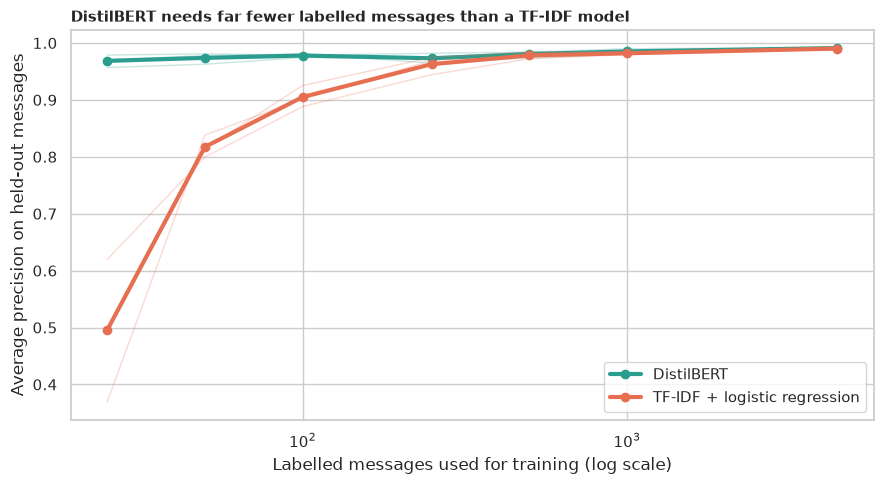

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in [("DistilBERT", TEAL), ("TF-IDF + logistic regression", ORANGE)]:
    sub = curve[curve["model"] == name]
    for _, grp in sub.groupby("seed"):
        ax.plot(grp["n"], grp["ap"], color=color, alpha=0.25, lw=1)
    mean = sub.groupby("n")["ap"].mean()
    ax.plot(mean.index, mean.values, color=color, lw=3, marker="o", label=name)
ax.set_xscale("log")
ax.set_xlabel("Labelled messages used for training (log scale)")
ax.set_ylabel("Average precision on held-out messages")
ax.set_title(
    "DistilBERT needs far fewer labelled messages than a TF-IDF model",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "02_learning_curve.png", dpi=150)
plt.show()

**How to read this:**

- **With almost no data, DistilBERT is far ahead:** with 25 training messages the average precision is **0.969** against **0.496**; with 50 it is **0.974** against **0.817**; with 100 **0.978** against **0.905**.
- **The gap closes quickly:** at 250 messages **0.973** against **0.963**; at 500 **0.980** against **0.978**; at 1,000 **0.985** against **0.982**; with all 4,459 **0.991** against **0.990**. Accuracy tells the same story (0.979 vs 0.871 at 25; 0.993 vs 0.990 at 4,459).
- **Across all 21 paired runs DistilBERT is better by 0.103 in average precision, better in 19 of 21 (Wilcoxon p = 1.3e-4).** The sizes are not independent (the same pool, and the large gaps come from the three smallest), so this p-value is only a summary; the picture in the figure is the evidence. **We reject H₀.**
- **The lesson:** DistilBERT's real value is when you have **dozens, not thousands,** of labelled examples. With thousands, a fast classical model is as good.

## 9. H3: does DistilBERT see through disguised spam?

*What:* spammers dodge word filters by swapping letters for look-alike digits ("FREE prize" becomes "FR33 pr1z3"). On the **149 spam messages** of the first held-out fold, we swap each of the letters e, o, a, i, s for a digit with probability **0, 0.2, 0.4 or 0.6**, and measure how many each model still catches. The models are the ones trained on that fold's training part (the same models as before, without retraining on disguised text). We compare at the highest level with an exact McNemar test. *Why:* a classifier that has memorised words breaks when the words change; one that has read the world should cope.

In [8]:
def obfuscate(message: str, gen: np.random.Generator, p: float) -> str:
    """Disguises a message the way spammers do: letters swapped for look-alike digits.

    Args:
        message: The original text.
        gen: Random number generator.
        p: Chance of swapping each eligible letter.

    Returns:
        The disguised message (e.g. "FREE prize" becomes "FR33 pr1z3").
    """
    table = {"e": "3", "o": "0", "a": "4", "i": "1", "s": "5"}
    return "".join(
        table[c.lower()] if c.lower() in table and gen.random() < p else c for c in message
    )


test_idx0 = folds[0][1]
spam_test = test_idx0[y[test_idx0] == 1]
model0, base0 = fold_models[0]
levels = [0.0, 0.2, 0.4, 0.6]
rows = []
disguised_at = {}
for level in levels:
    gen = np.random.default_rng(SEED)
    disguised = [obfuscate(m, gen, level) for m in texts.iloc[spam_test]]
    disguised_at[level] = disguised
    ids, mask = encode_texts(disguised)
    for name, prob in [
        ("DistilBERT", spam_probability(model0, ids, mask)),
        ("TF-IDF + logistic regression", base0.predict_proba(disguised)[:, 1]),
    ]:
        caught = prob > 0.5
        low, high = proportion_confint(int(caught.sum()), len(caught), method="wilson")
        rows.append(
            {"model": name, "level": level, "recall": caught.mean(), "ci_low": low, "ci_high": high}
        )
obf = pd.DataFrame(rows)
print(f"Spam messages in the held-out fold: {len(spam_test)}")
print(obf.pivot(index="level", columns="model", values="recall").round(3).to_string())
at = obf[obf["level"] == 0.6].set_index("model")
for name in at.index:
    print(
        f"  at 0.6: {name} {at.loc[name, 'recall']:.3f} "
        f"({at.loc[name, 'ci_low']:.3f} to {at.loc[name, 'ci_high']:.3f})"
    )
ids, mask = encode_texts(disguised_at[0.6])
bert_caught = spam_probability(model0, ids, mask) > 0.5
base_caught = base0.predict_proba(disguised_at[0.6])[:, 1] > 0.5
mc = mcnemar(
    [
        [int((bert_caught & base_caught).sum()), int((bert_caught & ~base_caught).sum())],
        [int((~bert_caught & base_caught).sum()), int((~bert_caught & ~base_caught).sum())],
    ],
    exact=True,
)
print(
    f"At 0.6: DistilBERT catches and baseline misses {int((bert_caught & ~base_caught).sum())}, "
    f"the reverse {int((~bert_caught & base_caught).sum())}; exact McNemar p = {fmt_p(mc.pvalue)}"
)

Spam messages in the held-out fold: 149
model  DistilBERT  TF-IDF + logistic regression
level                                          
0.0         0.960                         0.946
0.2         0.966                         0.926
0.4         0.973                         0.906
0.6         0.993                         0.872
  at 0.6: DistilBERT 0.993 (0.963 to 0.999)
  at 0.6: TF-IDF + logistic regression 0.872 (0.809 to 0.917)
At 0.6: DistilBERT catches and baseline misses 18, the reverse 0; exact McNemar p = 7.6e-06


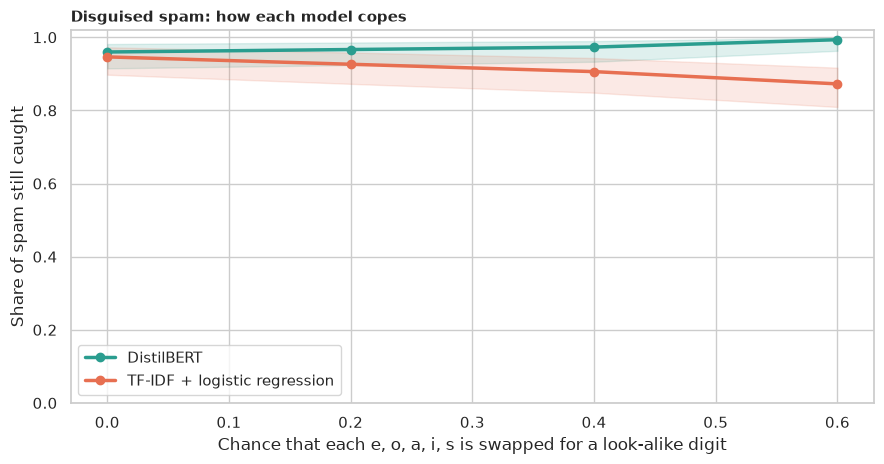

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for name, color in [("DistilBERT", TEAL), ("TF-IDF + logistic regression", ORANGE)]:
    sub = obf[obf["model"] == name]
    ax.plot(sub["level"], sub["recall"], marker="o", lw=2.5, color=color, label=name)
    ax.fill_between(sub["level"], sub["ci_low"], sub["ci_high"], color=color, alpha=0.15)
ax.set_xlabel("Chance that each e, o, a, i, s is swapped for a look-alike digit")
ax.set_ylabel("Share of spam still caught")
ax.set_ylim(0, 1.02)
ax.set_title("Disguised spam: how each model copes", loc="left", fontweight="bold", fontsize=11)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "03_obfuscation.png", dpi=150)
plt.show()

**How to read this:**

- **The baseline is hurt by the disguise:** its spam recall falls from **94.6%** with no disguise to **92.6%, 90.6%** and **87.2%** at levels 0.2, 0.4 and 0.6.
- **DistilBERT's recall does not fall; it rises:** **96.0%** with no disguise, then **96.6%, 97.3%** and **99.3%** (95% CI at level 0.6: 96.3% to 99.9%). At level 0.6 DistilBERT catches **18** disguised spam messages that the baseline misses, and the baseline catches **0** that DistilBERT misses (exact McNemar p = **8e-6**). **We reject H₀.**
- **Read the rise with care:** we only disguised *spam*, never ham. A model that has learned "digits in the middle of words mean spam" would also catch more as the disguise grows, and would flag disguised good messages. This test shows that the baseline is fragile, but **not** that DistilBERT understands the disguise; we did not test disguised ham.

## 10. H4: can we trust its confidence, and what does a mistake cost?

*What:* two questions about the probability each model reports.

1. **Calibration:** when a model says "97% sure", is it right 97% of the time? The **expected calibration error (ECE)** is the average gap between stated confidence and actual accuracy (0 is perfectly honest), with a bootstrap interval.
2. **Cost:** a false alarm (a good message lost in the spam folder) is worse than a spam that slips through. If a false alarm costs **10** and a missed spam **1**, the **total cost** of each model at several decision thresholds is *10 x false alarms + missed spam*.

All numbers use the 5,574 out-of-fold predictions. *Why:* a probability is only useful if it is honest, and the best threshold depends on the price of each mistake, not on accuracy.

In [10]:
def expected_calibration_error(truth: np.ndarray, prob: np.ndarray, bins: int = 10) -> float:
    """Average gap between stated confidence and actual accuracy, weighted by bin size.

    Args:
        truth: True labels (1 = spam).
        prob: Predicted spam probabilities.
        bins: Number of equal-width bins.

    Returns:
        The expected calibration error (0 = perfectly honest).
    """
    conf = np.where(prob > 0.5, prob, 1 - prob)
    right = ((prob > 0.5) == truth).astype(float)
    edges = np.linspace(0.5, 1.0, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:], strict=True):
        pick = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if pick.any():
            total += pick.mean() * abs(right[pick].mean() - conf[pick].mean())
    return float(total)


rows = []
for name, prob in [("DistilBERT", oof_bert), ("TF-IDF + logistic regression", oof_base)]:
    ece = expected_calibration_error(y, prob)
    boot = []
    for _ in range(N_BOOTSTRAP):
        pick = rng.integers(0, len(y), len(y))
        boot.append(expected_calibration_error(y[pick], prob[pick]))
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append(
        {
            "model": name,
            "ECE": ece,
            "ci_low": low,
            "ci_high": high,
            "mean confidence": np.where(prob > 0.5, prob, 1 - prob).mean(),
            "accuracy": ((prob > 0.5) == y).mean(),
        }
    )
calib = pd.DataFrame(rows).set_index("model")
print(calib.round(4).to_string())
cost_rows = []
for name, prob in [("DistilBERT", oof_bert), ("TF-IDF + logistic regression", oof_base)]:
    for threshold in (0.5, 0.2, 0.8, 0.95):
        pred = prob > threshold
        cost = 10 * int(((pred == 1) & (y == 0)).sum()) + int(((pred == 0) & (y == 1)).sum())
        cost_rows.append(
            {
                "model": name,
                "threshold": threshold,
                "false alarms": int(((pred == 1) & (y == 0)).sum()),
                "missed spam": int(((pred == 0) & (y == 1)).sum()),
                "cost (10:1)": cost,
            }
        )
cost_table = pd.DataFrame(cost_rows)
print("\nErrors and cost (a false alarm costs 10, a missed spam 1) at several thresholds:")
print(cost_table.to_string(index=False))

                                 ECE  ci_low  ci_high  mean confidence  accuracy
model                                                                           
DistilBERT                    0.0061  0.0042   0.0085           0.9975    0.9917
TF-IDF + logistic regression  0.0091  0.0075   0.0119           0.9822    0.9887

Errors and cost (a false alarm costs 10, a missed spam 1) at several thresholds:
                       model  threshold  false alarms  missed spam  cost (10:1)
                  DistilBERT       0.50            21           25          235
                  DistilBERT       0.20            26           24          284
                  DistilBERT       0.80            15           28          178
                  DistilBERT       0.95             9           35          125
TF-IDF + logistic regression       0.50             4           59           99
TF-IDF + logistic regression       0.20            26           27          287
TF-IDF + logistic regression      

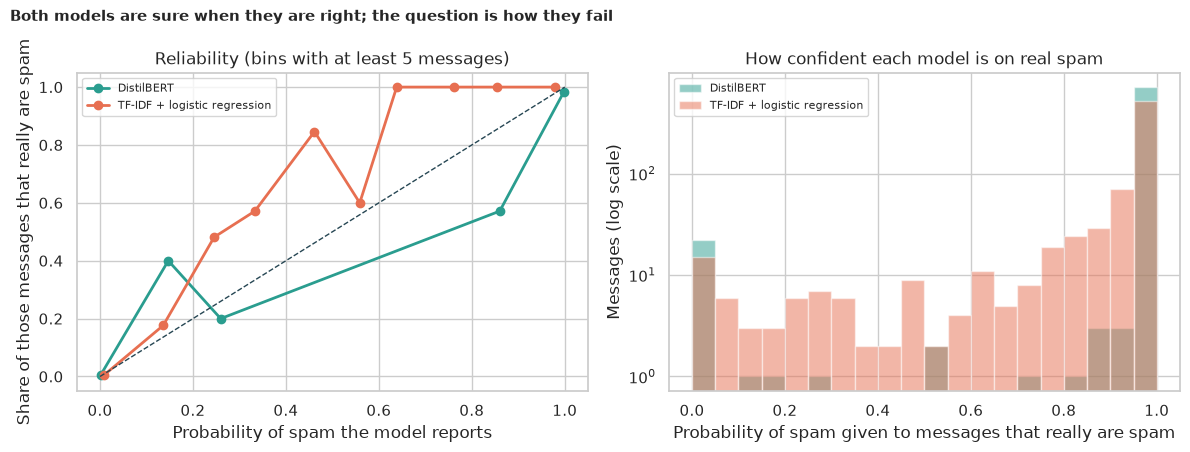

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, prob, color in [
    ("DistilBERT", oof_bert, TEAL),
    ("TF-IDF + logistic regression", oof_base, ORANGE),
]:
    edges = np.linspace(0, 1, 11)
    which = np.clip(np.digitize(prob, edges) - 1, 0, 9)
    xs, ys, ns = [], [], []
    for b in range(10):
        pick = which == b
        if pick.sum() >= 5:
            xs.append(prob[pick].mean())
            ys.append(y[pick].mean())
            ns.append(pick.sum())
    axes[0].plot(xs, ys, marker="o", color=color, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], color=NAVY, ls="--", lw=1)
axes[0].set_xlabel("Probability of spam the model reports")
axes[0].set_ylabel("Share of those messages that really are spam")
axes[0].set_title("Reliability (bins with at least 5 messages)")
axes[0].legend(fontsize=8)
for name, prob, color in [
    ("DistilBERT", oof_bert, TEAL),
    ("TF-IDF + logistic regression", oof_base, ORANGE),
]:
    axes[1].hist(prob[y == 1], bins=np.linspace(0, 1, 21), alpha=0.5, color=color, label=name)
axes[1].set_yscale("log")
axes[1].set_xlabel("Probability of spam given to messages that really are spam")
axes[1].set_ylabel("Messages (log scale)")
axes[1].set_title("How confident each model is on real spam")
axes[1].legend(fontsize=8)
fig.suptitle(
    "Both models are sure when they are right; the question is how they fail",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_calibration.png", dpi=150)
plt.show()

**How to read this:**

- **Both are well calibrated, and slightly over-confident:** ECE is **0.0061** (95% CI 0.0042 to 0.0085) for DistilBERT and **0.0091** (0.0075 to 0.0119) for the baseline. DistilBERT's average stated confidence is **99.75%** while it is right **99.17%** of the time, so its "sure" is a little too sure. The intervals do not overlap, but both gaps are under 1 point: **honest enough for both models**.
- **When a false alarm costs 10 times a miss, the baseline is cheaper:** at the default threshold of 0.5 DistilBERT costs **235** (21 false alarms, 25 missed spam) against **99** for the baseline (4 false alarms, 59 missed spam).
- **DistilBERT's best threshold is high:** at 0.95 it costs **125** (9 false alarms, 35 missed spam); at 0.8 **178**. Even tuned, it does not beat the baseline's **99** at 0.5 in this cost model. Raising the baseline's threshold to 0.95 would make it much worse (232), so the threshold has to be chosen for each model.
- **The winner depends on the price list,** not on the accuracy: with a 1:1 cost DistilBERT is cheaper (46 against 63 mistakes at 0.5).

In [12]:
wrong_bert = np.flatnonzero((oof_bert > 0.5) != y)
wrong_base = np.flatnonzero((oof_base > 0.5) != y)
both = np.intersect1d(wrong_bert, wrong_base)
print(
    f"DistilBERT mistakes: {len(wrong_bert)}; baseline mistakes: {len(wrong_base)}; "
    f"mistakes made by both: {len(both)}"
)
print("\nMessages only DistilBERT gets wrong:")
for i in np.setdiff1d(wrong_bert, wrong_base)[:4]:
    print(
        f"  true {'spam' if y[i] else 'ham'}, DistilBERT {oof_bert[i]:.2f}, baseline "
        f"{oof_base[i]:.2f}: {texts.iloc[i][:100]!r}"
    )
print("Messages only the baseline gets wrong:")
for i in np.setdiff1d(wrong_base, wrong_bert)[:4]:
    print(
        f"  true {'spam' if y[i] else 'ham'}, DistilBERT {oof_bert[i]:.2f}, baseline "
        f"{oof_base[i]:.2f}: {texts.iloc[i][:100]!r}"
    )
print("Messages both get wrong:")
for i in both[:4]:
    print(
        f"  true {'spam' if y[i] else 'ham'}, DistilBERT {oof_bert[i]:.2f}, baseline "
        f"{oof_base[i]:.2f}: {texts.iloc[i][:100]!r}"
    )

DistilBERT mistakes: 46; baseline mistakes: 63; mistakes made by both: 24

Messages only DistilBERT gets wrong:
  true ham, DistilBERT 0.92, baseline 0.23: "Hi! You just spoke to MANEESHA V. We'd like to know if you were satisfied with the experience. Reply"
  true ham, DistilBERT 1.00, baseline 0.03: 'MY NO. IN LUTON 0125698789 RING ME IF UR AROUND! H*'
  true spam, DistilBERT 0.03, baseline 0.67: 'You have an important customer service announcement from PREMIER.'
  true ham, DistilBERT 0.75, baseline 0.18: 'Yun ah.the ubi one say if ü wan call by tomorrow.call 67441233 look for irene.ere only got bus8,22,6'
Messages only the baseline gets wrong:
  true spam, DistilBERT 1.00, baseline 0.42: "FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it s"
  true ham, DistilBERT 0.00, baseline 0.53: 'Waiting for your call.'
  true spam, DistilBERT 1.00, baseline 0.47: 'SMS. ac sun0819 posts HELLO:"You seem cool, wanted to say hi. HI!!!" Stop? Send S

**How to read this:**

- **The models fail differently.** Messages **only DistilBERT** gets wrong include genuine-looking customer-service wording and phone numbers in friendly messages (a friend's "RING ME IF UR AROUND" with a number is called spam with probability 1.00).
- **Messages only the baseline gets wrong** are spam with unusual surface forms that DistilBERT recognises ("FreeMsg Hey there darling...", "Cost 10p"), and a short, plain ham ("Waiting for your call.") that the baseline scores 0.53.
- **24 messages are wrong for both:** jokes and horoscope-style texts labelled spam ("Divorce Barbie"), which look like ordinary messages. These are probably label noise or promotional texts, and no model of the text alone can fix them.

## 11. 🎯 Takeaways

1. **The legacy 99.4% measured a leaky split;** it replays at 99.37%, but 11.3% of the test messages had a twin in the training set. With duplicates grouped, DistilBERT scores 99.17% accuracy.
2. **On plenty of data, DistilBERT barely beats a fast baseline:** average precision 0.9893 against 0.9887 pooled, a McNemar edge of 39 against 22 messages (p = 0.040), and ahead in only 3 of 5 folds.
3. **Its edge is with little data:** with 25 labelled messages 0.969 against 0.496 in average precision; the gap is gone by about 500 messages.
4. **The baseline is fragile to disguise; DistilBERT is not (but see the caveat):** the baseline's recall falls from 94.6% to 87.2% as letters become digits, DistilBERT's rises to 99.3% (we did not disguise ham).
5. **A pretrained model is not automatically the cheaper one:** with a false alarm costing 10 times a miss, the baseline's total cost is 99 against DistilBERT's 125 at its best threshold, and 235 at 0.5, because DistilBERT raises more false alarms (21 against 4).
6. **Pick the metric before the model:** the same two models swap places depending on whether you care about ranking, recall, false alarms or cost.

## 12. ⚠️ Limitations

- **One dataset, English, older messages (collected before 2013, mostly from the UK and Singapore).** Today's spam (links, short codes, other languages) looks different, and so do users' habits.
- **The McNemar edge in H1 is narrow** (p = 0.040); with a different split seed it could move to either side of 0.05.
- **The learning curve uses one held-out fold and 3 subsets per size,** and the 21 pairs in the test are not independent.
- **Disguise was applied to spam only,** so H3 cannot say whether DistilBERT understands the disguise or reacts to digits; we also did not retrain on disguised text.
- **The disguise test uses the models of one fold** (149 spam messages).
- **Cost ratio and thresholds are a choice:** the 10 to 1 ratio is an example, and thresholds were chosen on the same predictions we report.
- **DistilBERT was fine-tuned with one set of settings** (learning rate, passes) and not tuned; a tuned baseline and a tuned DistilBERT might differ.
- **Duplicate detection is exact** (lower-cased, stripped text); near-duplicates remain across folds, which flatters both models slightly.
- **No fairness or privacy review:** the messages are real people's texts.